# Escalonamento e vazamento de dados

## Importando bibliotecas e dados

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.knn_utils import criar_rodar, f1_teste_com_vazamento

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

df = pd.read_csv("../data/raw/dupla_08.csv")

In [2]:
X = df.drop(columns="classe")
y = df["classe"]

train_df = pd.read_csv("../data/processed/train.csv", index_col="id")
test_df = pd.read_csv("../data/processed/test.csv", index_col="id")
X_train, y_train = train_df.drop(columns="classe"), train_df["classe"]
X_test, y_test = test_df.drop(columns="classe"), test_df["classe"]

rodar = criar_rodar(X_train, X_test, y_train, y_test)

## Investigação da escala dos atributos

Comparamos três preparações com k = 5: dados originais (A), `MinMaxScaler` (B) e `StandardScaler` (C). Em B e C o escalonador é ajustado só com o treino e depois aplicado ao teste.

In [3]:
baseline = pd.read_csv("../data/processed/baseline.csv", index_col="modelo")
exps = {"B - MinMaxScaler": "minmax", "C - StandardScaler": "standard"}
novos = pd.DataFrame({nome: rodar(tipo, k=5) for nome, tipo in exps.items()}).T[["f1_treino", "f1_teste", "gap", "acc_teste", "prec_teste", "rec_teste"]]

res_escala = pd.concat([baseline, novos])
res_escala.index.name = "modelo"
res_escala.to_csv("../data/processed/escalonamento.csv")

tab_escala = res_escala.copy()
tab_escala.index.name = None
tab_escala.columns = ["F1 treino", "F1 teste", "Gap", "Acurácia teste", "Precision teste", "Recall teste"]
tab_escala

,F1 treino,F1 teste,Gap,Acurácia teste,Precision teste,Recall teste
A - dados originais,0.7569,0.6125,0.1444,0.6129,0.6127,0.6125
B - MinMaxScaler,0.8621,0.8000,0.0621,0.8000,0.8000,0.8000
C - StandardScaler,0.8470,0.7677,0.0794,0.7677,0.7677,0.7677


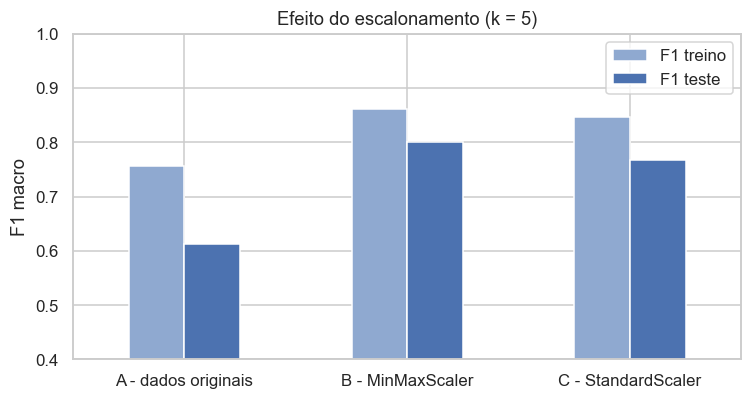

In [4]:
ax = tab_escala[["F1 treino", "F1 teste"]].plot.bar(figsize=(7, 3.8), rot=0, color=["#8FA9D0", "#4C72B0"])
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("F1 macro")
ax.set_title("Efeito do escalonamento (k = 5)")
plt.tight_layout()
plt.show()

### Resultados da investigação

* MinMaxScaler: melhor F1 (0,800), contra 0,768 do StandardScaler e 0,613 sem escala.
* O escalonamento reduziu o domínio do `indice_03` e melhorou o resultado.

### Problema metodológico do procedimento apresentado no enunciado

```python
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)
```

O código funciona, mas gera data leakage ao ajustar o scaler usando também os dados de teste, podendo deixar a métrica artificialmente melhor. O correto é separar primeiro, ajustar o scaler apenas no treino e depois aplicá-lo ao teste.


```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   
X_test_s = scaler.transform(X_test)        
```

Abaixo comparamos os dois procedimentos.

In [5]:
sc_total = StandardScaler().fit(X)
sc_treino = StandardScaler().fit(X_train)
estat = pd.DataFrame({
    "média (todos)": sc_total.mean_, "média (só treino)": sc_treino.mean_,
    "desvio (todos)": sc_total.scale_, "desvio (só treino)": sc_treino.scale_,
}, index=X.columns)
estat.round(3)

,média (todos),média (só treino),desvio (todos),desvio (só treino)
indice_01,2.1420,0.5770,46.7120,45.7170
indice_02,-2.2880,-2.3190,20.5800,20.4840
indice_03,5209.0370,5369.3610,16023.0310,15534.7610
indice_04,-3.3050,-3.3210,0.3080,0.3080
indice_05,-757.1380,-787.8310,789.8140,775.6750
indice_06,6.9500,7.1470,8.0480,8.0110
indice_07,-3.9430,-4.0640,4.8700,4.7710
indice_08,-4.2000,-4.1860,2.1890,2.1850
indice_09,-5.5220,-5.5280,1.5690,1.5470


In [6]:
comp = pd.DataFrame({
    "com vazamento (fit em X inteiro)": [f1_teste_com_vazamento(S, X, y) for S in (StandardScaler, MinMaxScaler)],
    "correto (fit só no treino)": [tab_escala.loc["C - StandardScaler", "F1 teste"],
                                   tab_escala.loc["B - MinMaxScaler", "F1 teste"]],
}, index=["StandardScaler", "MinMaxScaler"])
comp

,com vazamento (fit em X inteiro),correto (fit só no treino)
StandardScaler,0.7677,0.7677
MinMaxScaler,0.8193,0.8000


* As estatísticas mudam quando o teste entra no `fit`: a média de `indice_03`, por exemplo, é 5209 com todos os dados e 5369 só com o treino.
* O vazamento teve pouco efeito no StandardScaler, mas no MinMaxScaler o F1 subiu de 0,800 para 0,819.
* Para evitar vazamento de informação, o scaler é ajustado somente nos dados de treino e aplicado dentro do Pipeline durante a validação cruzada.